# Session 2 - a complete fuzzy inference, step by step
Chain: **fuzzification -> rule activation (AND = min) -> implication -> aggregation -> crisp output**. Engine: `fuzzy.py` (written from scratch, no library).

In [1]:
import sys, math, numpy as np, matplotlib.pyplot as plt
sys.path.insert(0, '..')
from fuzzy import trap, tri, LinguisticVariable, Rule, MamdaniEngine, SugenoEngine
from fuzzy_design import build_goal_engine

## 1. Handout exercise: u = 0.25
Bas = trap(0, 0, 0.2, 0.6), Haut = trap(0.2, 0.6, 1, 1).

By hand: 0.25 lies on the falling edge of Bas: (0.6 - 0.25) / (0.6 - 0.2) = **0.875**; on the rising edge of Haut: (0.25 - 0.2) / (0.6 - 0.2) = **0.125**.

Sugeno (constants 0.2 and 0.8): z* = (0.875 x 0.2 + 0.125 x 0.8) / (0.875 + 0.125) = **0.275**.

In [2]:
u = LinguisticVariable('u', 0, 1, [trap('Bas', 0, 0, 0.2, 0.6), trap('Haut', 0.2, 0.6, 1, 1)])
y = LinguisticVariable('y', 0, 1, [tri('Faible', 0, 0.2, 0.5), tri('Fort', 0.5, 0.8, 1.0)])
rules = [Rule(('Bas',), (('y', 'Faible'),)), Rule(('Haut',), (('y', 'Fort'),))]
sug = SugenoEngine([u], {'y': y}, rules, {'y': {'Faible': 0.2, 'Fort': 0.8}})
lam_bas, lam_haut = u.fuzzify(0.25)
print('lambda_Bas =', lam_bas, ' lambda_Haut =', lam_haut)
print('Sugeno output =', sug.infer((0.25,))['y'])
assert abs(sug.infer((0.25,))['y'] - 0.275) < 1e-12

lambda_Bas = 0.875  lambda_Haut = 0.12499999999999999
Sugeno output = 0.275


## 2. Mamdani version
Constants replaced by fuzzy sets on [0, 1]: **Faible = tri(0, 0.2, 0.5)**, **Fort = tri(0.5, 0.8, 1.0)**.

Implication min(lambda_j, mu_Bj(z)), aggregation max, discrete centre of gravity z* = sum z mu(z) / sum mu(z) on a uniform grid. The result depends on the shapes and the grid.

In [3]:
def by_hand(n):
    num = den = 0.0
    for i in range(n):
        z = i / (n - 1)
        f = max(0, min(z / 0.2, (0.5 - z) / 0.3))
        g = max(0, min((z - 0.5) / 0.3, (1 - z) / 0.2))
        mu = max(min(lam_bas, f), min(lam_haut, g))
        num += z * mu; den += mu
    return num / den

for n in (11, 101, 1001):
    mam = MamdaniEngine([u], {'y': y}, rules, n)
    print(f'{n:5d} points: engine = {mam.infer((0.25,))["y"]:.6f}   explicit sums = {by_hand(n):.6f}')

   11 points: engine = 0.324638   explicit sums = 0.324638
  101 points: engine = 0.333544   explicit sums = 0.333544
 1001 points: engine = 0.333654   explicit sums = 0.333654


With 11 points the hand computation fits on paper:

In [4]:
z = np.linspace(0, 1, 11)
mam = MamdaniEngine([u], {'y': y}, rules, 11)
agg = mam.explain((0.25,))['agg']['y']
for zi, m in zip(z, agg): print(f'z = {zi:.1f}  mu = {m:.4f}  z*mu = {zi*m:.4f}')
print('sum mu =', agg.sum().round(4), ' sum z*mu =', (z*agg).sum().round(4), ' z* =', ((z*agg).sum()/agg.sum()).round(6))

z = 0.0  mu = 0.0000  z*mu = 0.0000
z = 0.1  mu = 0.5000  z*mu = 0.0500
z = 0.2  mu = 0.8750  z*mu = 0.1750
z = 0.3  mu = 0.6667  z*mu = 0.2000
z = 0.4  mu = 0.3333  z*mu = 0.1333
z = 0.5  mu = 0.0000  z*mu = 0.0000
z = 0.6  mu = 0.1250  z*mu = 0.0750
z = 0.7  mu = 0.1250  z*mu = 0.0875
z = 0.8  mu = 0.1250  z*mu = 0.1000
z = 0.9  mu = 0.1250  z*mu = 0.1125
z = 1.0  mu = 0.0000  z*mu = 0.0000
sum mu = 2.875  sum z*mu = 0.9333  z* = 0.324638


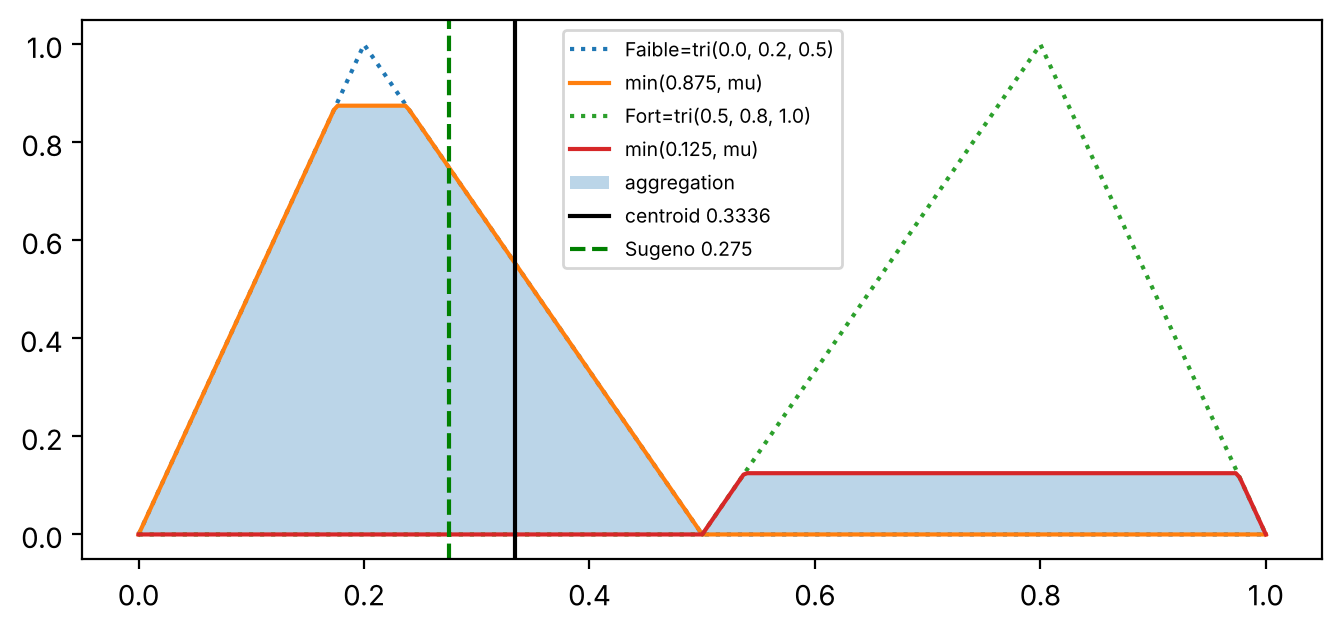

In [5]:
ex = MamdaniEngine([u], {'y': y}, rules, 301).explain((0.25,))
zz = ex['grid']['y']
fig, ax = plt.subplots(figsize=(8, 3.5))
for s, lam in zip(y.sets, (lam_bas, lam_haut)):
    ax.plot(zz, s.eval(zz), ':', label=repr(s))
    ax.plot(zz, np.minimum(lam, s.eval(zz)), label=f'min({lam:.3f}, mu)')
ax.fill_between(zz, ex['agg']['y'], alpha=.3, label='aggregation')
ax.axvline(ex['out']['y'], color='k', label=f"centroid {ex['out']['y']:.4f}")
ax.axvline(0.275, color='g', ls='--', label='Sugeno 0.275'); ax.legend(fontsize=7); plt.show()

## 3. A full inference of the navigation controller
rho = 2.0 m, alpha = 0.9 rad (goal on the left).

In [6]:
for kind in ('mamdani', 'sugeno'):
    e = build_goal_engine(kind)
    ex = e.explain((2.0, 0.9))
    print(kind.upper())
    for var, mu in zip(e.inputs, ex['mus']):
        print('  ', var.name, dict(zip(var.names, np.round(mu, 3))))
    for r, lam in zip(e.rules, ex['lambda']):
        if lam > 0: print(f'   lambda = {lam:.3f}  ', r.text(e.inputs, e.outputs))
    print('   output:', {k: round(v, 4) for k, v in ex['out'].items()})

MAMDANI
   rho {'Proche': np.float64(0.0), 'Moyenne': np.float64(0.75), 'Loin': np.float64(0.0)}
   alpha {'GN': np.float64(0.0), 'N': np.float64(0.0), 'Z': np.float64(0.0), 'P': np.float64(0.429), 'GP': np.float64(0.625)}
   lambda = 0.429   IF rho is Moyenne AND alpha is P THEN v is L, omega is G
   lambda = 0.625   IF rho is Moyenne AND alpha is GP THEN v is S, omega is TG
   output: {'v': 0.1049, 'omega': 0.8788}
SUGENO
   rho {'Proche': np.float64(0.0), 'Moyenne': np.float64(0.75), 'Loin': np.float64(0.0)}
   alpha {'GN': np.float64(0.0), 'N': np.float64(0.0), 'Z': np.float64(0.0), 'P': np.float64(0.429), 'GP': np.float64(0.625)}
   lambda = 0.429   IF rho is Moyenne AND alpha is P THEN v is L, omega is G
   lambda = 0.625   IF rho is Moyenne AND alpha is GP THEN v is S, omega is TG
   output: {'v': 0.0488, 'omega': 1.0153}


## 4. Policy when no rule fires
The partitions cover their whole domain (coverage > 0), so this cannot happen with the handout sets. The engine still handles it: `infer` returns `None`, increments `n_inactive` (diagnostic), and the controller applies **(v, omega) = (0, 0)**. Out-of-domain inputs are saturated to the domain and counted (`n_out_of_domain`).

In [7]:
from fuzzy_design import goal_inputs, motion_outputs, avoid_inputs
for v in (*goal_inputs(), *motion_outputs(), *avoid_inputs()):
    print(f'{v.name:8s} coverage = {v.coverage():.3f}')
rho, _ = goal_inputs(); rho.fuzzify(-2); rho.fuzzify(30)
print('out-of-domain events counted:', rho.n_out_of_domain)

rho      coverage = 0.242
alpha    coverage = 0.334
v        coverage = 0.286
omega    coverage = 0.200
d_front  coverage = 0.308
beta     coverage = 0.500
out-of-domain events counted: 2
